<a href="https://colab.research.google.com/github/RozieKii/localTest/blob/main/context_window_management.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2.2: Context Window Management

## Key Insight
> **Why can't you just paste a 500-page book into the prompt?**

## Learning Objectives
By the end of this notebook, you will:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.2: Context Window Management - Ready to start!')
print('\nTopics covered:')
print('  - Understanding token limits and context windows')
print('  - Token counting and estimation techniques')
print('  - Context compression strategies')
print('  - Conversation history management')
print('  - Sliding window approaches')


✅ Week 2.2: Context Window Management - Ready to start!

Topics covered:
  - Understanding token limits and context windows
  - Token counting and estimation techniques
  - Context compression strategies
  - Conversation history management
  - Sliding window approaches


---
## Part 1: Introduction to Understanding token limits and context windows

Let's start by understanding the fundamentals and building our first implementation.

In [2]:

class ContextWindowManager:
    """Estimate token usage and manage a limited context window."""

    def __init__(self, max_tokens=1000):
        self.max_tokens = max_tokens
        self.data = []

    def estimate_tokens(self, text):
        """Estimate tokens using roughly 4 characters per token."""
        return max(1, len(text) // 4) if text else 0

    def process(self, input_data):
        """Check whether the input fits within the context budget."""
        if not isinstance(input_data, str):
            raise TypeError("input_data must be a string")

        estimated_tokens = self.estimate_tokens(input_data)
        fits = estimated_tokens <= self.max_tokens

        result = {
            "text": input_data,
            "estimated_tokens": estimated_tokens,
            "max_tokens": self.max_tokens,
            "tokens_remaining": max(0, self.max_tokens - estimated_tokens),
            "fits": fits
        }

        self.data.append(result)
        return result


# Test the class
manager = ContextWindowManager(max_tokens=1000)

result = manager.process("This is a test of context window management.")

print(f"Estimated tokens: {result['estimated_tokens']}")
print(f"Maximum tokens: {result['max_tokens']}")
print(f"Tokens remaining: {result['tokens_remaining']}")
print(f"Fits in context window: {result['fits']}")


Estimated tokens: 11
Maximum tokens: 1000
Tokens remaining: 989
Fits in context window: True


### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [3]:

class BasicContextManager:
    """Estimate token usage and check context limits."""

    def __init__(self, max_tokens=1000):
        if not isinstance(max_tokens, int) or isinstance(max_tokens, bool):
            raise TypeError("max_tokens must be an integer")
        if max_tokens <= 0:
            raise ValueError("max_tokens must be positive")

        self.max_tokens = max_tokens

    def estimate_tokens(self, text):
        """Rough estimate: approximately 1 token per 4 characters."""
        if not isinstance(text, str):
            raise TypeError("Input must be a string")

        return (len(text) + 3) // 4

    def process(self, text):
        """Return token estimate and whether the text fits."""
        tokens = self.estimate_tokens(text)

        return {
            "text": text,
            "estimated_tokens": tokens,
            "max_tokens": self.max_tokens,
            "tokens_remaining": max(0, self.max_tokens - tokens),
            "fits": tokens <= self.max_tokens
        }


# Test 1: Short text
manager = BasicContextManager(max_tokens=10)
result = manager.process("Hello world!")

print("Test 1:", result)
assert result["estimated_tokens"] == 3
assert result["fits"] is True

# Test 2: Empty text
result = manager.process("")
print("Test 2:", result)
assert result["estimated_tokens"] == 0
assert result["fits"] is True

# Test 3: Text exceeding the budget
result = manager.process("A" * 100)
print("Test 3:", result)
assert result["estimated_tokens"] == 25
assert result["fits"] is False

# Test 4: Invalid input
try:
    manager.process(123)
except TypeError as error:
    print("Test 4: Error handled:", error)
else:
    raise AssertionError("Expected a TypeError")

# Test 5: Invalid context limit
try:
    BasicContextManager(max_tokens=0)
except ValueError as error:
    print("Test 5: Error handled:", error)
else:
    raise AssertionError("Expected a ValueError")

print("\n✅ All Exercise 1 tests passed!")


Test 1: {'text': 'Hello world!', 'estimated_tokens': 3, 'max_tokens': 10, 'tokens_remaining': 7, 'fits': True}
Test 2: {'text': '', 'estimated_tokens': 0, 'max_tokens': 10, 'tokens_remaining': 10, 'fits': True}
Test 3: {'text': 'AAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAA', 'estimated_tokens': 25, 'max_tokens': 10, 'tokens_remaining': 0, 'fits': False}
Test 4: Error handled: Input must be a string
Test 5: Error handled: max_tokens must be positive

✅ All Exercise 1 tests passed!


---
## Part 2: Token counting and estimation techniques

Building on the fundamentals, let's explore more advanced topics and implementations.

In [4]:
from typing import List, Any, Dict
import json

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """Estimate token usage for a list of text items."""
    max_tokens = kwargs.get("max_tokens", 1000)
    results = []

    if not isinstance(max_tokens, int) or isinstance(max_tokens, bool):
        raise TypeError("max_tokens must be an integer")
    if max_tokens <= 0:
        raise ValueError("max_tokens must be positive")

    for item in data:
        if not isinstance(item, str):
            raise TypeError("Every item in data must be a string")

        # Rough estimate: 1 token per 4 characters
        estimated_tokens = (len(item) + 3) // 4

        results.append({
            "text": item,
            "estimated_tokens": estimated_tokens
        })

    total_tokens = sum(item["estimated_tokens"] for item in results)

    return {
        "processed": len(data),
        "items": results,
        "total_estimated_tokens": total_tokens,
        "max_tokens": max_tokens,
        "fits": total_tokens <= max_tokens
    }


# Example usage
sample_data = [
    "Understanding token limits",
    "Context windows manage available input",
    "AI models process text in tokens"
]

output = advanced_function(sample_data, max_tokens=100)
print(json.dumps(output, indent=2))

{
  "processed": 3,
  "items": [
    {
      "text": "Understanding token limits",
      "estimated_tokens": 7
    },
    {
      "text": "Context windows manage available input",
      "estimated_tokens": 10
    },
    {
      "text": "AI models process text in tokens",
      "estimated_tokens": 8
    }
  ],
  "total_estimated_tokens": 25,
  "max_tokens": 100,
  "fits": true
}


### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [5]:
from typing import List, Any, Dict
import json

class IntermediateContextManager:
    """Estimate token usage and check context-window limits."""

    def __init__(self, max_tokens: int = 1000):
        if not isinstance(max_tokens, int) or isinstance(max_tokens, bool):
            raise TypeError("max_tokens must be an integer.")
        if max_tokens <= 0:
            raise ValueError("max_tokens must be greater than zero.")

        self.max_tokens = max_tokens

    def estimate_tokens(self, text: str) -> int:
        """Estimate tokens using roughly 1 token per 4 characters."""
        if not isinstance(text, str):
            raise TypeError("Input text must be a string.")

        return (len(text) + 3) // 4

    def process(self, data: List[str]) -> Dict[str, Any]:
        """Estimate token usage for multiple text items."""
        if not isinstance(data, list):
            raise TypeError("data must be a list of strings.")

        if not all(isinstance(item, str) for item in data):
            raise TypeError("Every item in data must be a string.")

        item_results = [
            {
                "text": item,
                "estimated_tokens": self.estimate_tokens(item)
            }
            for item in data
        ]

        total_tokens = sum(
            item["estimated_tokens"] for item in item_results
        )

        return {
            "processed": len(data),
            "items": item_results,
            "total_estimated_tokens": total_tokens,
            "max_tokens": self.max_tokens,
            "tokens_remaining": max(0, self.max_tokens - total_tokens),
            "fits": total_tokens <= self.max_tokens
        }


# Test 1: Normal input
manager = IntermediateContextManager(max_tokens=20)
result = manager.process([
    "Hello world!",
    "Learning about AI",
    "Context windows"
])
print("Test 1: Normal input")
print(json.dumps(result, indent=2))

assert result["processed"] == 3
assert result["fits"] is True

# Test 2: Empty list
empty_result = manager.process([])
assert empty_result["processed"] == 0
assert empty_result["total_estimated_tokens"] == 0
print("\nTest 2 passed: Empty list")

# Test 3: Input exceeding the token limit
long_result = manager.process(["A" * 100])
assert long_result["fits"] is False
assert long_result["tokens_remaining"] == 0
print("Test 3 passed: Context limit exceeded")

# Test 4: Invalid data type
try:
    manager.process("This is not a list")
except TypeError as error:
    print("Test 4 passed:", error)

# Test 5: Invalid item inside list
try:
    manager.process(["valid text", 123])
except TypeError as error:
    print("Test 5 passed:", error)

# Test 6: Invalid token limit
try:
    IntermediateContextManager(max_tokens=0)
except ValueError as error:
    print("Test 6 passed:", error)

print("\nAll Exercise 2 tests completed!")

Test 1: Normal input
{
  "processed": 3,
  "items": [
    {
      "text": "Hello world!",
      "estimated_tokens": 3
    },
    {
      "text": "Learning about AI",
      "estimated_tokens": 5
    },
    {
      "text": "Context windows",
      "estimated_tokens": 4
    }
  ],
  "total_estimated_tokens": 12,
  "max_tokens": 20,
  "tokens_remaining": 8,
  "fits": true
}

Test 2 passed: Empty list
Test 3 passed: Context limit exceeded
Test 4 passed: data must be a list of strings.
Test 5 passed: Every item in data must be a string.
Test 6 passed: max_tokens must be greater than zero.

All Exercise 2 tests completed!


---
## Part 3: Context compression strategies

Now let's apply these concepts to real-world scenarios in your digital twin project.

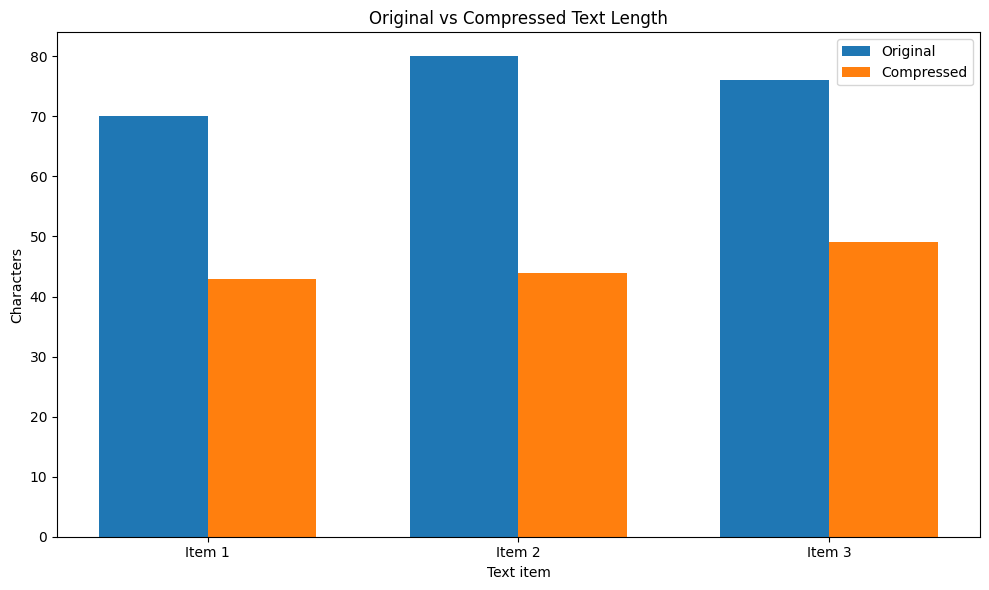

Item 1: 70 original characters → 43 compressed characters
Item 2: 80 original characters → 44 compressed characters
Item 3: 76 original characters → 49 compressed characters


In [6]:
import matplotlib.pyplot as plt
from typing import List, Any

def compress_text(text: str, max_chars: int = 200) -> str:
    """Keep text within a character limit, preserving whole words where possible."""
    if not isinstance(text, str):
        raise TypeError("text must be a string.")
    if not isinstance(max_chars, int) or isinstance(max_chars, bool):
        raise TypeError("max_chars must be an integer.")
    if max_chars < 0:
        raise ValueError("max_chars cannot be negative.")

    if len(text) <= max_chars:
        return text

    if max_chars == 0:
        return ""

    shortened = text[:max_chars].rsplit(" ", 1)[0]
    return shortened if shortened else text[:max_chars]


def visualize_results(data: List[Any]):
    """Compare original and compressed text lengths."""
    if not isinstance(data, list):
        raise TypeError("data must be a list of strings.")

    if not all(isinstance(item, str) for item in data):
        raise TypeError("Every item in data must be a string.")

    if not data:
        raise ValueError("Please provide at least one text item.")

    original_lengths = [len(text) for text in data]
    compressed_texts = [compress_text(text, 50) for text in data]
    compressed_lengths = [len(text) for text in compressed_texts]

    positions = list(range(len(data)))
    width = 0.35

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.bar(
        [p - width / 2 for p in positions],
        original_lengths,
        width,
        label="Original"
    )
    ax.bar(
        [p + width / 2 for p in positions],
        compressed_lengths,
        width,
        label="Compressed"
    )

    ax.set_title("Original vs Compressed Text Length")
    ax.set_xlabel("Text item")
    ax.set_ylabel("Characters")
    ax.set_xticks(positions)
    ax.set_xticklabels([f"Item {p + 1}" for p in positions])
    ax.legend()

    plt.tight_layout()
    plt.show()

    for i, (original, compressed) in enumerate(
        zip(original_lengths, compressed_lengths), start=1
    ):
        print(
            f"Item {i}: {original} original characters → "
            f"{compressed} compressed characters"
        )


# Example data
sample_data = [
    "A digital twin learns about a user's goals, preferences, and progress.",
    "Context compression reduces unnecessary text while retaining useful information.",
    "Token limits determine how much information an AI model can process at once."
]

visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

ERROR:root:Invalid input type: int


Test 1 passed: Short text
Test 2 passed: Long text compressed
Test 3 passed: Empty text
Test 4 passed: input_data must be a string.
Test 5 passed: max_tokens must be greater than zero.
Test 6 passed: History stays within its limit


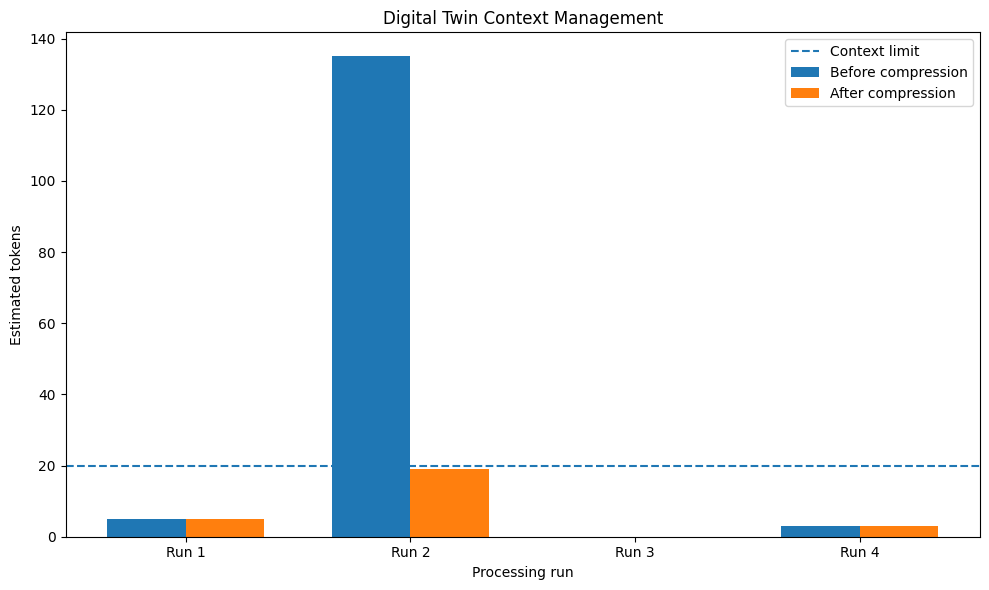

Test 7 passed: Visualization displayed

All Exercise 3 tests passed!


In [7]:
import logging
import matplotlib.pyplot as plt
from typing import List, Dict, Any


# Configure logging
logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s: %(message)s"
)


class ProductionSystem:
    """
    Manage a digital twin's text context.

    Features:
    - Estimate token usage (approximately 1 token per 4 characters).
    - Validate input and context limits.
    - Compress text to fit a character budget.
    - Maintain a bounded conversation history.
    - Log processing and error information.
    - Visualize original versus compressed text sizes.

    Note: Token estimates and compression are simplified examples.
    They are not exact model tokenization or semantic summarization.
    """

    def __init__(self, max_tokens: int = 500, history_limit: int = 5):
        if not isinstance(max_tokens, int) or isinstance(max_tokens, bool):
            raise TypeError("max_tokens must be an integer.")
        if max_tokens <= 0:
            raise ValueError("max_tokens must be greater than zero.")

        if not isinstance(history_limit, int) or isinstance(history_limit, bool):
            raise TypeError("history_limit must be an integer.")
        if history_limit <= 0:
            raise ValueError("history_limit must be greater than zero.")

        self.max_tokens = max_tokens
        self.history_limit = history_limit
        self.history = []
        self.results = []

        logging.info(
            "ProductionSystem initialized: max_tokens=%s, history_limit=%s",
            max_tokens, history_limit
        )

    def estimate_tokens(self, text: str) -> int:
        """Estimate token count using approximately 4 characters per token."""
        if not isinstance(text, str):
            raise TypeError("Text must be a string.")

        return (len(text) + 3) // 4

    def compress_text(self, text: str, max_chars: int) -> str:
        """Shorten text to a character budget, preserving whole words where possible."""
        if not isinstance(text, str):
            raise TypeError("Text to compress must be a string.")

        if not isinstance(max_chars, int) or isinstance(max_chars, bool):
            raise TypeError("max_chars must be an integer.")

        if max_chars < 0:
            raise ValueError("max_chars cannot be negative.")

        if len(text) <= max_chars:
            return text

        if max_chars == 0:
            return ""

        shortened = text[:max_chars].rsplit(" ", 1)[0]
        return shortened if shortened else text[:max_chars]

    def process(self, input_data: str) -> Dict[str, Any]:
        """
        Process one text input and return token and compression statistics.
        """
        if not isinstance(input_data, str):
            logging.error("Invalid input type: %s", type(input_data).__name__)
            raise TypeError("input_data must be a string.")

        original_tokens = self.estimate_tokens(input_data)
        fits = original_tokens <= self.max_tokens

        # If text exceeds the budget, shorten it to approximately
        # max_tokens * 4 characters.
        if fits:
            processed_text = input_data
        else:
            processed_text = self.compress_text(
                input_data, self.max_tokens * 4
            )

        processed_tokens = self.estimate_tokens(processed_text)

        # Keep only the most recent entries in the conversation history.
        self.history.append(processed_text)
        self.history = self.history[-self.history_limit:]

        result = {
            "original_characters": len(input_data),
            "processed_characters": len(processed_text),
            "original_estimated_tokens": original_tokens,
            "processed_estimated_tokens": processed_tokens,
            "max_tokens": self.max_tokens,
            "fits_before_compression": fits,
            "fits_after_compression": processed_tokens <= self.max_tokens,
            "compression_applied": processed_text != input_data,
            "processed_text": processed_text,
            "history_entries": len(self.history)
        }

        self.results.append(result)

        logging.info(
            "Processed input: original=%s tokens, processed=%s tokens",
            original_tokens, processed_tokens
        )

        return result

    def visualize_results(self):
        """Plot original and processed text lengths for successful runs."""
        if not self.results:
            raise ValueError("No results to visualize. Process some text first.")

        positions = list(range(len(self.results)))
        original = [r["original_estimated_tokens"] for r in self.results]
        processed = [r["processed_estimated_tokens"] for r in self.results]

        width = 0.35
        fig, ax = plt.subplots(figsize=(10, 6))

        ax.bar(
            [p - width / 2 for p in positions],
            original,
            width,
            label="Before compression"
        )
        ax.bar(
            [p + width / 2 for p in positions],
            processed,
            width,
            label="After compression"
        )

        ax.axhline(
            self.max_tokens,
            linestyle="--",
            label="Context limit"
        )

        ax.set_title("Digital Twin Context Management")
        ax.set_xlabel("Processing run")
        ax.set_ylabel("Estimated tokens")
        ax.set_xticks(positions)
        ax.set_xticklabels([f"Run {p + 1}" for p in positions])
        ax.legend()

        plt.tight_layout()
        plt.show()


# -------------------------
# Tests
# -------------------------

system = ProductionSystem(max_tokens=20, history_limit=3)

# Test 1: Short text
result1 = system.process("Hello, digital twin!")
assert result1["fits_before_compression"] is True
assert result1["compression_applied"] is False
print("Test 1 passed: Short text")

# Test 2: Long text
result2 = system.process(
    "Digital twins use context to remember goals, preferences, "
    "learning progress, tasks, and useful information. " * 5
)
assert result2["compression_applied"] is True
assert result2["fits_after_compression"] is True
print("Test 2 passed: Long text compressed")

# Test 3: Empty text
result3 = system.process("")
assert result3["processed_estimated_tokens"] == 0
print("Test 3 passed: Empty text")

# Test 4: Invalid input
try:
    system.process(123)
except TypeError as error:
    print("Test 4 passed:", error)
else:
    raise AssertionError("Expected a TypeError for non-string input")

# Test 5: Invalid configuration
try:
    ProductionSystem(max_tokens=0)
except ValueError as error:
    print("Test 5 passed:", error)
else:
    raise AssertionError("Expected a ValueError for max_tokens=0")

# Test 6: History limit
system.process("Fourth entry")
assert len(system.history) <= 3
print("Test 6 passed: History stays within its limit")

# Test 7: Visualization
system.visualize_results()
print("Test 7 passed: Visualization displayed")

print("\nAll Exercise 3 tests passed!")

---
## Summary & Key Takeaways

### What We Learned:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete Understanding token limits and context windows System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code


--- Context Report ---
{
  "max_tokens": 1000,
  "response_reserve": 150,
  "available_input_tokens": 850,
  "original_section_tokens": {
    "instructions": 13,
    "user_message": 16,
    "retrieved_notes": 46,
    "history": 21
  },
  "final_section_tokens": {
    "instructions": 13,
    "user_message": 16,
    "retrieved_notes": 46,
    "history": 21
  },
  "original_total_tokens": 96,
  "final_total_tokens": 96,
  "tokens_remaining": 754,
  "compression_applied": false,
  "fits": true,
  "processed_sections": {
    "instructions": "You are a helpful digital twin learning assistant.",
    "user_message": "Explain context windows and help me plan my next study session.",
    "retrieved_notes": "Context windows limit how much text a model can process at once. Token counts depend on the model tokenizer. Compression reduces input size, while sliding windows keep recent history.",
    "history": "The learner is studying AI agents.\nThe current topic is context window management."
  }
}

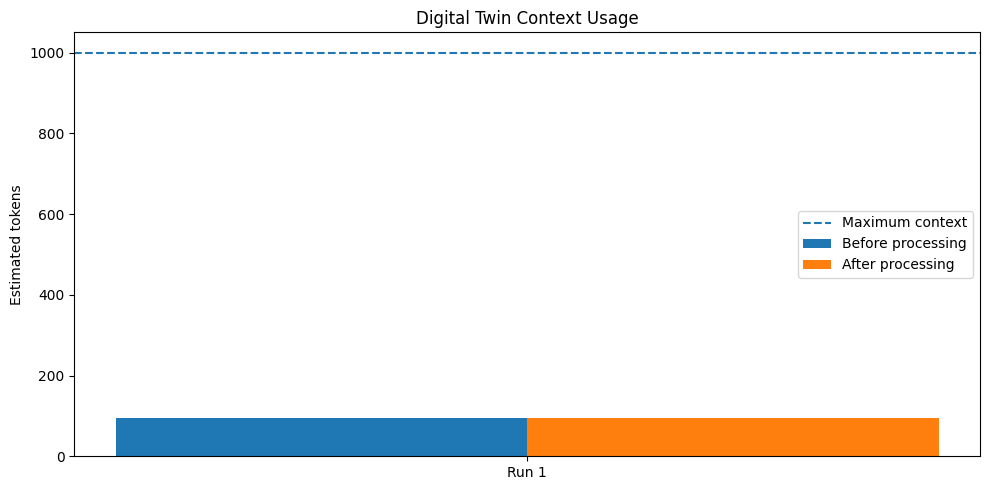


--- JSON Export Preview ---
[
  {
    "max_tokens": 1000,
    "response_reserve": 150,
    "available_input_tokens": 850,
    "original_section_tokens": {
      "instructions": 13,
      "user_message": 16,
      "retrieved_notes": 46,
      "history": 21
    },
    "final_section_tokens": {
      "instructions": 13,
      "user_message": 16,
      "retrieved_notes": 46,
      "history": 21
    },
    "original_total_tokens": 96,
    "final_total_tokens": 96,
    "tokens_remaining": 754,
    "compression_applied": false,
    "fits": true,
    "processed_sections": {
      "instructions": "You are a helpful digital twin learning assistant.",
      "user_message": "Explain context windows and help me plan my next study session.",
      "retrieved_notes": "Context windows limit how much text a model can process at once. Token counts depend on the model tokenizer. Compression reduces input size, while sliding windows keep recent history.",
      "history": "The learner is studying AI agen

In [8]:

import json
import logging
import matplotlib.pyplot as plt
from collections import deque
from typing import Any, Dict, List


# -------------------------------
# 1. Logging
# -------------------------------

logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s: %(message)s"
)
logger = logging.getLogger("DigitalTwinContext")


# -------------------------------
# 2. Context Window Manager
# -------------------------------

class DigitalTwinContextManager:
    """
    Manage context for a digital twin.

    Features:
    - Approximate token estimation.
    - Context budgeting for multiple sections.
    - Basic text compression.
    - Sliding-window conversation history.
    - Logging, testing support, visualization, and JSON export.

    Token estimates use approximately 1 token per 4 characters.
    This is a heuristic, not an actual model tokenizer.
    """

    def __init__(self, max_tokens: int = 1000, history_limit: int = 5):
        self._validate_positive_int(max_tokens, "max_tokens")
        self._validate_positive_int(history_limit, "history_limit")

        self.max_tokens = max_tokens
        self.history_limit = history_limit
        self.history = deque(maxlen=history_limit)
        self.results = []

        logger.info("Context manager initialized.")

    @staticmethod
    def _validate_positive_int(value: int, name: str) -> None:
        if not isinstance(value, int) or isinstance(value, bool):
            raise TypeError(f"{name} must be an integer.")
        if value <= 0:
            raise ValueError(f"{name} must be greater than zero.")

    @staticmethod
    def estimate_tokens(text: str) -> int:
        """Estimate token count from character length."""
        if not isinstance(text, str):
            raise TypeError("Text must be a string.")
        return (len(text) + 3) // 4

    @staticmethod
    def compress_text(text: str, max_chars: int) -> str:
        """
        Shorten text to a character limit.
        This truncates; it does not preserve meaning like an AI summary.
        """
        if not isinstance(text, str):
            raise TypeError("Text must be a string.")
        if not isinstance(max_chars, int) or isinstance(max_chars, bool):
            raise TypeError("max_chars must be an integer.")
        if max_chars < 0:
            raise ValueError("max_chars cannot be negative.")

        if len(text) <= max_chars:
            return text
        if max_chars == 0:
            return ""

        shortened = text[:max_chars].rsplit(" ", 1)[0]
        return shortened if shortened else text[:max_chars]

    def add_history(self, message: str) -> None:
        """Keep only the most recent messages."""
        if not isinstance(message, str):
            raise TypeError("History message must be a string.")

        self.history.append(message)
        logger.debug("History now contains %d messages.", len(self.history))

    def process(
        self,
        instructions: str = "",
        user_message: str = "",
        retrieved_notes: str = "",
        response_reserve: int = 100
    ) -> Dict[str, Any]:
        """
        Estimate total context usage and shorten text sections if needed.

        response_reserve is the token budget reserved for the model's reply.
        """
        sections = {
            "instructions": instructions,
            "user_message": user_message,
            "retrieved_notes": retrieved_notes
        }

        for name, value in sections.items():
            if not isinstance(value, str):
                raise TypeError(f"{name} must be a string.")

        self._validate_positive_int(response_reserve, "response_reserve")

        # Include recent conversation messages in the budget.
        history_text = "\n".join(self.history)

        original_tokens = {
            name: self.estimate_tokens(value)
            for name, value in sections.items()
        }
        original_tokens["history"] = self.estimate_tokens(history_text)

        available_input_tokens = self.max_tokens - response_reserve

        if available_input_tokens < 0:
            raise ValueError(
                "response_reserve cannot exceed the context limit."
            )

        # Give each section a character budget based on its share of
        # the available input budget. This is a simple allocation strategy.
        section_order = [
            "instructions", "user_message", "retrieved_notes", "history"
        ]
        section_values = {
            **sections,
            "history": history_text
        }

        total_original = sum(original_tokens.values())
        compressed_values = dict(section_values)

        if total_original > available_input_tokens:
            remaining_chars = available_input_tokens * 4

            # Preserve instructions and the current user message first.
            for name in section_order:
                text_value = section_values[name]
                if not text_value or remaining_chars <= 0:
                    compressed_values[name] = ""
                    continue

                kept = self.compress_text(text_value, remaining_chars)
                compressed_values[name] = kept
                remaining_chars -= len(kept)

            logger.warning("Context exceeded budget; shortening text sections.")

        final_tokens = {
            name: self.estimate_tokens(value)
            for name, value in compressed_values.items()
        }
        total_final = sum(final_tokens.values())

        result = {
            "max_tokens": self.max_tokens,
            "response_reserve": response_reserve,
            "available_input_tokens": available_input_tokens,
            "original_section_tokens": original_tokens,
            "final_section_tokens": final_tokens,
            "original_total_tokens": total_original,
            "final_total_tokens": total_final,
            "tokens_remaining": max(0, available_input_tokens - total_final),
            "compression_applied": compressed_values != section_values,
            "fits": total_final <= available_input_tokens,
            "processed_sections": compressed_values
        }

        self.results.append(result)
        logger.info(
            "Context processed: %d estimated tokens -> %d estimated tokens.",
            total_original,
            total_final
        )

        return result

    def visualize_results(self) -> None:
        """Plot token estimates before and after processing."""
        if not self.results:
            raise ValueError("Process some context before visualizing results.")

        labels = [f"Run {i + 1}" for i in range(len(self.results))]
        before = [r["original_total_tokens"] for r in self.results]
        after = [r["final_total_tokens"] for r in self.results]

        positions = list(range(len(labels)))
        width = 0.35

        fig, ax = plt.subplots(figsize=(10, 5))
        ax.bar(
            [p - width / 2 for p in positions],
            before,
            width,
            label="Before processing"
        )
        ax.bar(
            [p + width / 2 for p in positions],
            after,
            width,
            label="After processing"
        )
        ax.axhline(
            self.max_tokens,
            linestyle="--",
            label="Maximum context"
        )

        ax.set_xticks(positions)
        ax.set_xticklabels(labels)
        ax.set_ylabel("Estimated tokens")
        ax.set_title("Digital Twin Context Usage")
        ax.legend()
        plt.tight_layout()
        plt.show()

    def export_results(self) -> str:
        """Export results as a JSON string for inspection or saving."""
        return json.dumps(self.results, indent=2, ensure_ascii=False)


# -------------------------------
# 3. Example digital twin context
# -------------------------------

manager = DigitalTwinContextManager(
    max_tokens=1000,
    history_limit=3
)

manager.add_history("The learner is studying AI agents.")
manager.add_history("The current topic is context window management.")

result = manager.process(
    instructions="You are a helpful digital twin learning assistant.",
    user_message="Explain context windows and help me plan my next study session.",
    retrieved_notes=(
        "Context windows limit how much text a model can process at once. "
        "Token counts depend on the model tokenizer. "
        "Compression reduces input size, while sliding windows keep recent history."
    ),
    response_reserve=150
)

print("\n--- Context Report ---")
print(json.dumps(result, indent=2, ensure_ascii=False))


# -------------------------------
# 4. Automated tests
# -------------------------------

def run_tests():
    test_manager = DigitalTwinContextManager(
        max_tokens=50,
        history_limit=2
    )

    # Test 1: Token estimate
    assert test_manager.estimate_tokens("Hello") == 2

    # Test 2: Empty string
    assert test_manager.estimate_tokens("") == 0

    # Test 3: Compression
    compressed = test_manager.compress_text("one two three four", 7)
    assert len(compressed) <= 7

    # Test 4: History limit
    test_manager.add_history("first")
    test_manager.add_history("second")
    test_manager.add_history("third")
    assert len(test_manager.history) == 2
    assert list(test_manager.history) == ["second", "third"]

    # Test 5: Normal processing
    output = test_manager.process(
        instructions="Help the user.",
        user_message="Explain AI.",
        retrieved_notes="AI uses learned patterns.",
        response_reserve=10
    )
    assert output["fits"] is True

    # Test 6: Invalid input type
    try:
        test_manager.estimate_tokens(123)
    except TypeError:
        pass
    else:
        raise AssertionError("Non-string input should raise TypeError.")

    # Test 7: Invalid configuration
    try:
        DigitalTwinContextManager(max_tokens=0)
    except ValueError:
        pass
    else:
        raise AssertionError("Zero context limit should raise ValueError.")

    # Test 8: Invalid response reserve
    try:
        test_manager.process(response_reserve=100)
    except ValueError:
        pass
    else:
        raise AssertionError("Reserve above context limit should raise ValueError.")

    # Test 9: Export results
    exported = test_manager.export_results()
    assert isinstance(json.loads(exported), list)

    print("✅ All 9 tests passed!")


run_tests()

# -------------------------------
# 5. Visualization and export
# -------------------------------

manager.visualize_results()

print("\n--- JSON Export Preview ---")
print(manager.export_results()[:1000])
